# 6주차 과제 — sEMG 팔 동작 분류
이동현 21113718 · Step 2의 3주차 실습

## 중요한 재현 가정
- 데이터 README는 bandpass 열이 이미 필터링된 신호라고 설명합니다.
  강의 실습 연결을 위해 이번에도 노치·대역통과 필터를 추가 적용합니다.
  따라서 센서 원신호에 처음 필터를 적용한 결과라고 표현하지 않습니다.
- mark의 0→비0 변화를 5초 시행 후보의 기준점으로 사용합니다.
  마커가 동작 시작인지 시행 시작인지는 확정되지 않았습니다.
- 분석 구간은 **이벤트 기준 +1.5초부터 2초**라는 가정입니다.
  4번 그래프를 확인하고 이 가정과 실제 신호의 관계를 보고서에 남깁니다.
- 동일 시행의 모든 윈도우는 같은 집합에 배정합니다.
  같은 사람과 같은 기록 파일의 다른 시행은 양쪽 집합에 포함될 수 있습니다.
- fold마다 scaler와 모델을 새로 학습합니다. 특징 계산은 각 시행 안에서 독립적입니다.
- hold-out 및 전체 데이터 5-fold를 별도로 보고합니다.
  전체 데이터 CV에는 hold-out 대상도 포함됩니다. 독립 외부 테스트로 해석하지 않습니다.

## 1. 설치
코랩 첫 셀입니다.

In [ ]:
%pip install -q numpy pandas scipy scikit-learn xgboost matplotlib joblib

## 2. 공통 설정과 가져오기
설정은 결과를 보기 전에 고정합니다. 이후 설정을 바꾸면 변경 사실을 기록합니다.

In [ ]:
from pathlib import Path
import os, sys, json, time, platform, subprocess, shutil, zipfile
from itertools import combinations
import numpy as np
import pandas as pd
import scipy
from scipy.signal import butter, iirnotch, filtfilt
from scipy.stats import ttest_rel
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
import xgboost
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    def display(x): print(x)

ROOT = (Path('/content/semg_step2') if '__file__' not in globals()
        and Path('/content').exists() else Path.cwd())
ROOT.mkdir(parents=True, exist_ok=True)
RESULTS = ROOT / 'results'; FIGURES = ROOT / 'figures'
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
FS, WIN, HOP = 1000, 200, 100
TRIAL_LEN, SEG_START, SEG_LEN = 5000, 1500, 2000
SEED = 42
DATA_URL = 'https://github.com/TestUser-alt-dev/sEMG-Hand-Gesture-Elbow-Angle-Dataset.git'
DATA_REVISION = 'cb64ded658b83ae97e6388dd373efad0e97bc47c'
CHANNELS = [f'bandpass {i}' for i in range(1, 6)]
CONFIG = dict(fs=FS, window=WIN, hop=HOP, trial_len=TRIAL_LEN,
              segment_offset_from_mark=SEG_START, segment_len=SEG_LEN,
              seed=SEED, data_revision=DATA_REVISION,
              segmentation='mark rising edge + 1.5s for 2s (assumption)',
              filtering='additional notch60 Q30 then bandpass20-450 order4',
              cv_scope='all trials, separately from hold-out; not external test',
              macro_average=True, cv_std_ddof=0)
(RESULTS/'config.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
print('출력 폴더:', ROOT)

출력 폴더: /content/semg_step2


## 3. 데이터 다운로드
기존 dataset.npz 없이 시작할 수 있습니다. 데이터 버전을 고정합니다. 다운로드에는 시간이 걸릴 수 있습니다.

In [ ]:
SOURCE = ROOT / '_source_data'
if not SOURCE.exists():
    subprocess.run(['git', 'clone', '--depth', '1', DATA_URL, str(SOURCE)], check=True)
actual_revision = subprocess.check_output(
    ['git', '-C', str(SOURCE), 'rev-parse', 'HEAD'], text=True).strip()
if actual_revision != DATA_REVISION:
    subprocess.run(['git', '-C', str(SOURCE), 'fetch', '--depth', '1',
                    'origin', DATA_REVISION], check=True)
    subprocess.run(['git', '-C', str(SOURCE), 'checkout', '--detach',
                    DATA_REVISION], check=True)
files = sorted((SOURCE/'data').rglob('*.csv'))
assert len(files) == 64, f'예상 64개 파일, 실제 {len(files)}개: 경로 확인'

def file_label(p):
    subject, rest = p.stem.split('_', 1)
    angle, gesture = rest.split()
    gesture = {'fist':'fist', 'open':'open',
               'pro':'pronation', 'extor':'supination'}[gesture]
    return subject, f'{angle}_{gesture}'

print('파일 수:', len(files)); print('데이터 revision:', DATA_REVISION)
print(pd.Series([file_label(p)[1] for p in files]).value_counts().sort_index())

파일 수: 64
데이터 revision: cb64ded658b83ae97e6388dd373efad0e97bc47c
30_fist          8
30_open          8
30_pronation     8
30_supination    8
60_fist          8
60_open          8
60_pronation     8
60_supination    8
Name: count, dtype: int64


## 4. 이벤트 기준점 확인
첫 파일의 `mark`와 5채널 파형을 확인합니다. 세로선이 실제 근활성의 어느 부분인지 살펴봅니다.
원본 한 파일에서는 30개의 mark가 5초 간격으로 나타났습니다.
전체 파일의 검사는 다음 단계에서 수행합니다. 개수나 간격이 다르면 임의로 진행하지 않고 오류 내용을 확인합니다.
**여기까지 실행한 그래프와 마커 간격을 먼저 확인하는 것을 권장**

파일: a_30 extor.csv 배열: (151361, 8)
mark 기준점 개수: 30
처음 5개 기준점(행 번호): [   70  5070 10070 15070 20070]
기준점 간격(초): [5.]
onset 값별 개수: {0: 151360, 1: 1}


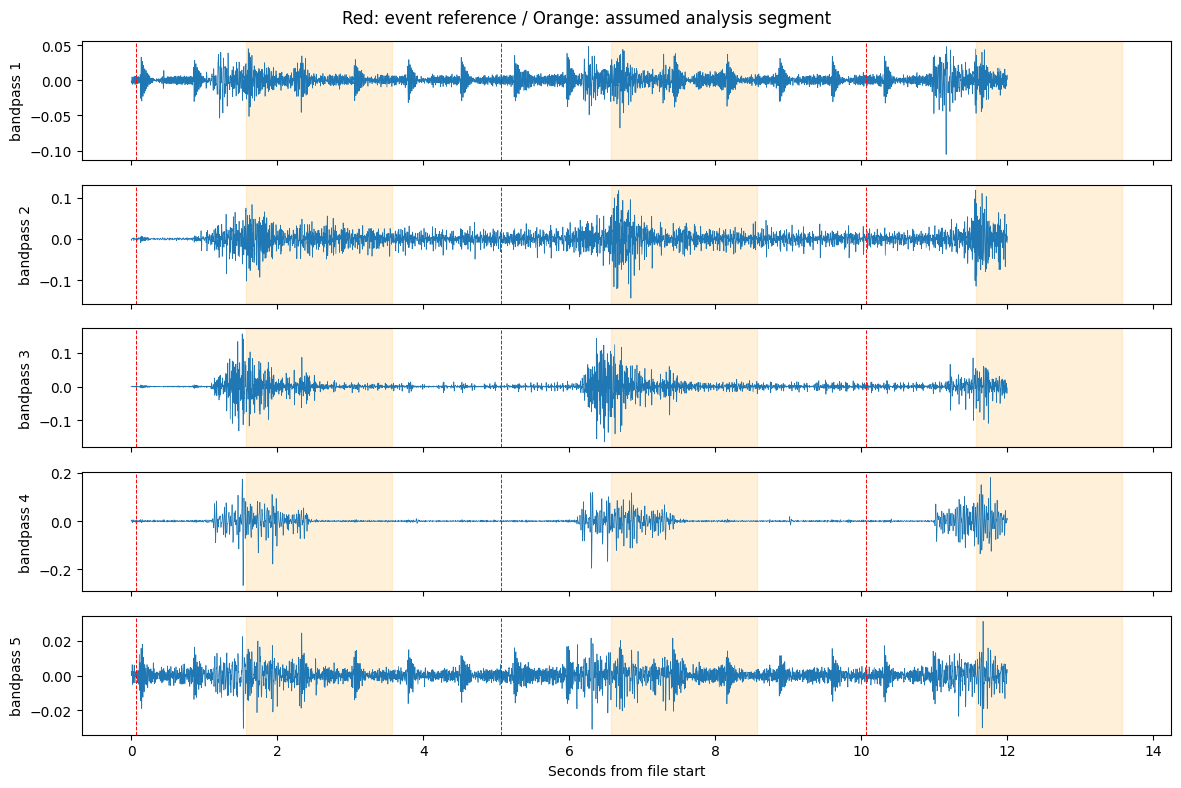

In [ ]:
def event_starts(df):
    m = pd.to_numeric(df['mark'], errors='raise').to_numpy() != 0
    return np.flatnonzero(m & ~np.r_[False, m[:-1]])

example = pd.read_csv(files[0])
starts = event_starts(example)
print('파일:', files[0].name, '배열:', example.shape)
print('mark 기준점 개수:', len(starts))
print('처음 5개 기준점(행 번호):', starts[:5])
print('기준점 간격(초):', np.unique(np.diff(starts) / FS))
print('onset 값별 개수:', example['onset'].value_counts().to_dict())
t = np.arange(min(len(example), 12000)) / FS
fig, axes = plt.subplots(5, 1, figsize=(12, 8), sharex=True)
for ch, ax in enumerate(axes):
    ax.plot(t, example[CHANNELS[ch]].to_numpy()[:len(t)], lw=0.5)
    for start in starts[starts < len(t)]:
        ax.axvline(start / FS, color='red', ls='--', lw=0.7)
        ax.axvspan((start+SEG_START)/FS, (start+SEG_START+SEG_LEN)/FS,
                   color='orange', alpha=0.15)
    ax.set_ylabel(CHANNELS[ch])
axes[-1].set_xlabel('Seconds from file start')
fig.suptitle('Red: event reference / Orange: assumed analysis segment')
fig.tight_layout(); fig.savefig(FIGURES/'event_alignment.png', dpi=160)
plt.show()

## 5. 전체 시행 후보의 특징 생성과 검사
mark 기준점으로 5초 구간을 구분한 뒤 각 구간 안에서만 필터를 적용합니다.
분석 시작점은 강의 예시의 1.5초를 마커에 대해 적용한 **추가 가정**입니다.
실제 동작 정렬을 검증했다고 쓰지 않습니다.

특징을 먼저 계산해 캐시하지만, 이는 각 시행에서만 독립적으로 계산하는 고정 변환입니다.
분할 때 시행 ID를 사용하므로 겹치는 윈도우는 서로 다른 집합에 들어가지 않습니다.
scaler의 통계는 이 단계에서 계산하지 않습니다.

In [ ]:
def preprocess(x, fs=FS):
    bn, an = iirnotch(60, 30, fs)
    x = filtfilt(bn, an, x, axis=0)
    b, a = butter(4, [20/(fs/2), 450/(fs/2)], btype='band')
    return filtfilt(b, a, x, axis=0)

def make_windows(x):
    return np.stack([x[i:i+WIN] for i in range(0, len(x)-WIN+1, HOP)])

def td_features(w, th=0.01):
    rms = np.sqrt(np.mean(w**2, axis=0))
    mav = np.mean(np.abs(w), axis=0)
    d = np.diff(w, axis=0)
    wl = np.sum(np.abs(d), axis=0)
    zc = np.sum((w[:-1]*w[1:] < 0) & (np.abs(d) >= th), axis=0)
    ssc = np.sum(d[:-1]*d[1:] < 0, axis=0)
    return np.concatenate([rms, mav, wl, zc, ssc])

X_parts, metadata, audit = [], [], []
for file_index, path in enumerate(files):
    df = pd.read_csv(path)
    subject, label = file_label(path)
    s = event_starts(df)
    dt = np.diff(df['time'].to_numpy(dtype=float))
    assert np.allclose(dt, 1/FS, atol=1e-7), f'{path.name}: time 간격이 일정하지 않습니다'
    assert len(s) == 30, f'{path.name}: mark {len(s)}개입니다. 예상 30개와 다르므로 확인이 필요합니다.'
    assert np.all(np.abs(np.diff(s)-TRIAL_LEN) <= 2), f'{path.name}: mark 간격을 확인하세요'
    signal = df[CHANNELS].to_numpy(dtype=np.float64)
    assert np.isfinite(signal).all(), f'{path.name}: NaN/Inf'
    audit.append(dict(file=path.name, subject=subject, label=label,
                      rows=len(df), events=len(s), first_event=int(s[0]),
                      last_event=int(s[-1])))
    for trial_no, start in enumerate(s):
        assert start+TRIAL_LEN <= len(signal), f'{path.name}: 마지막 5초 구간이 부족합니다'
        end = min(start+TRIAL_LEN, int(s[trial_no+1])) if trial_no+1 < len(s) else start+TRIAL_LEN
        trial = signal[start:end]
        seg = preprocess(trial)[SEG_START:SEG_START+SEG_LEN]
        windows = make_windows(seg)
        assert windows.shape == (19, 200, 5)
        features = np.stack([td_features(w) for w in windows])
        assert features.shape == (19, 25) and np.isfinite(features).all()
        trial_id = f'{path.stem}__trial{trial_no+1:02d}'
        X_parts.append(features)
        metadata.append(dict(trial_id=trial_id, subject=subject, label=label,
                             file=path.name, event_sample=int(start)))
    if (file_index+1) % 8 == 0:
        print(f'{file_index+1}/{len(files)} 파일 특징 생성 완료')

X = np.stack(X_parts)  # (trial, window, feature)
meta = pd.DataFrame(metadata)
le = LabelEncoder(); labels = le.fit_transform(meta['label'])
classes = le.classes_; class_ids = np.arange(len(classes))
assert X.shape == (1920, 19, 25) and len(classes) == 8
assert meta['trial_id'].is_unique
meta.to_csv(RESULTS/'trial_metadata.csv', index=False)
pd.DataFrame(audit).to_csv(RESULTS/'data_audit.csv', index=False)
np.savez_compressed(RESULTS/'features_unscaled.npz', X=X, y=labels,
                    trial_id=meta.trial_id.to_numpy(dtype=str), classes=classes)
print('특징 배열:', X.shape, '총 윈도우:', X.shape[0]*X.shape[1])
display(meta.groupby('label').size().rename('trial_count').to_frame())

8/64 파일 특징 생성 완료
16/64 파일 특징 생성 완료
24/64 파일 특징 생성 완료
32/64 파일 특징 생성 완료
40/64 파일 특징 생성 완료
48/64 파일 특징 생성 완료
56/64 파일 특징 생성 완료
64/64 파일 특징 생성 완료
특징 배열: (1920, 19, 25) 총 윈도우: 36480


,trial_count
label,
30_fist,240
30_open,240
30_pronation,240
30_supination,240
60_fist,240
60_open,240
60_pronation,240
60_supination,240


## 6. 동일 시행 단위 hold-out 분할
전체 1,920개 시행 후보를 80:20으로 나누면 1,536/384개입니다.
각 시행의 윈도우 19개를 펼치면 학습 29,184개, 테스트 7,296개입니다.
논문의 1,536/384는 세그먼트 수이며, 여기서의 모델 입력 표본 수와 구분합니다.
윈도우별 25차원을 별도 표본으로 사용하는 것은 강의 실습의 입력 구성 선택입니다.

In [ ]:
tr_i, te_i = train_test_split(np.arange(len(meta)), test_size=0.2,
                             stratify=labels, random_state=SEED)
assert set(tr_i).isdisjoint(te_i)
def flatten(indices):
    return X[indices].reshape(-1, 25), np.repeat(labels[indices], X.shape[1])
Xtr, ytr = flatten(tr_i); Xte, yte = flatten(te_i)
te_meta = meta.iloc[te_i].reset_index(drop=True)
holdout_manifest = meta.copy()
holdout_manifest['split'] = 'train'
holdout_manifest.loc[te_i, 'split'] = 'test'
holdout_manifest.to_csv(RESULTS/'holdout_manifest.csv', index=False)
summary = pd.DataFrame({'split':['train','test'], 'trials':[len(tr_i),len(te_i)],
                         'windows':[len(ytr),len(yte)], 'features':[25,25]})
display(summary); summary.to_csv(RESULTS/'dataset_summary.csv', index=False)
counts = pd.DataFrame({'train':np.bincount(ytr, minlength=8),
                       'test':np.bincount(yte, minlength=8)}, index=classes)
display(counts); counts.to_csv(RESULTS/'class_distribution.csv')
shared_subjects = sorted(set(meta.iloc[tr_i].subject) & set(te_meta.subject))
print('학습·테스트에 공통으로 포함된 참가자:', shared_subjects)

,split,trials,windows,features
0,train,1536,29184,25
1,test,384,7296,25


,train,test
30_fist,3648,912
30_open,3648,912
30_pronation,3648,912
30_supination,3648,912
60_fist,3648,912
60_open,3648,912
60_pronation,3648,912
60_supination,3648,912


학습·테스트에 공통으로 포함된 참가자: ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h']


## 7. 세 모델 학습과 hold-out 평가 및 계산 비용
강의의 SVM·RF·XGBoost 설정을 사용합니다. 표준화는 Pipeline 안에서 학습합니다.
Precision·Recall·F1은 macro 평균이며 예측이 없는 클래스는 0으로 처리합니다.
학습 시간은 scaler+모델 fit, 추론 시간은 이미 추출된 25D 특징 한 개의 scaler+predict입니다.
10회 예열 후 100회 평균을 측정하며 신호 수집·필터·특징 추출 시간은 제외합니다.

In [ ]:
models = {
 'SVM': Pipeline([('scaler', StandardScaler()), ('model',
     SVC(kernel='rbf', C=1.0, gamma='scale', decision_function_shape='ovr'))]),
 'RF': Pipeline([('scaler', StandardScaler()), ('model',
     RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1))]),
 'XGB': Pipeline([('scaler', StandardScaler()), ('model',
     XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
       subsample=0.9, colsample_bytree=0.8, random_state=SEED, n_jobs=2,
       eval_metric='mlogloss'))]),
}
def metrics(y, pred):
    return {'Accuracy':accuracy_score(y, pred),
      'Precision':precision_score(y, pred, labels=class_ids, average='macro', zero_division=0),
      'Recall':recall_score(y, pred, labels=class_ids, average='macro', zero_division=0),
      'F1-score':f1_score(y, pred, labels=class_ids, average='macro', zero_division=0)}

fitted, predictions, rows, costs = {}, {}, [], []
for name, prototype in models.items():
    model = clone(prototype)
    t0 = time.perf_counter(); model.fit(Xtr, ytr)
    train_seconds = time.perf_counter()-t0
    pred = model.predict(Xte)
    fitted[name], predictions[name] = model, pred
    rows.append({'Model':name, **metrics(yte, pred)})
    for _ in range(10): model.predict(Xte[:1])
    t0 = time.perf_counter()
    for _ in range(100): model.predict(Xte[:1])
    infer_ms = (time.perf_counter()-t0)/100*1000
    costs.append({'Model':name, 'Train_seconds':train_seconds,
                  'Inference_ms_per_window':infer_ms})
    print(name, '학습 및 평가 완료')
holdout = pd.DataFrame(rows).set_index('Model')
cost_table = pd.DataFrame(costs).set_index('Model')
display((holdout*100).round(2)); display(cost_table.round(4))
holdout.to_csv(RESULTS/'holdout_metrics.csv')
cost_table.to_csv(RESULTS/'computation_cost.csv')
prediction_table = pd.DataFrame({'trial_id':np.repeat(te_meta.trial_id.to_numpy(),19),
    'subject':np.repeat(te_meta.subject.to_numpy(),19), 'window':np.tile(np.arange(19),len(te_i)),
    'true':le.inverse_transform(yte)})
for name,pred in predictions.items(): prediction_table[name]=le.inverse_transform(pred)
prediction_table.to_csv(RESULTS/'holdout_predictions.csv',index=False)

SVM 학습 및 평가 완료
RF 학습 및 평가 완료
XGB 학습 및 평가 완료


,Accuracy,Precision,Recall,F1-score
Model,,,,
SVM,47.82,48.57,47.82,47.89
RF,65.27,65.44,65.27,65.28
XGB,63.58,63.77,63.58,63.60


,Train_seconds,Inference_ms_per_window
Model,,
SVM,59.5451,3.0172
RF,21.9710,34.9809
XGB,24.0205,4.1868


## 8. 세 모델의 혼동행렬과 오류 구조
행은 실제 클래스, 열은 예측 클래스입니다. 모델별 정답률은 행 합으로 나눈 재현율로 비교합니다.
오류를 ①동작 동일·각도 다름 ②각도 동일·동작 다름 ③둘 다 다름으로 분류합니다.
오류 개수는 관찰 사실이며, 근육·자세 등 원인은 별도 실험 전에는 가설입니다.

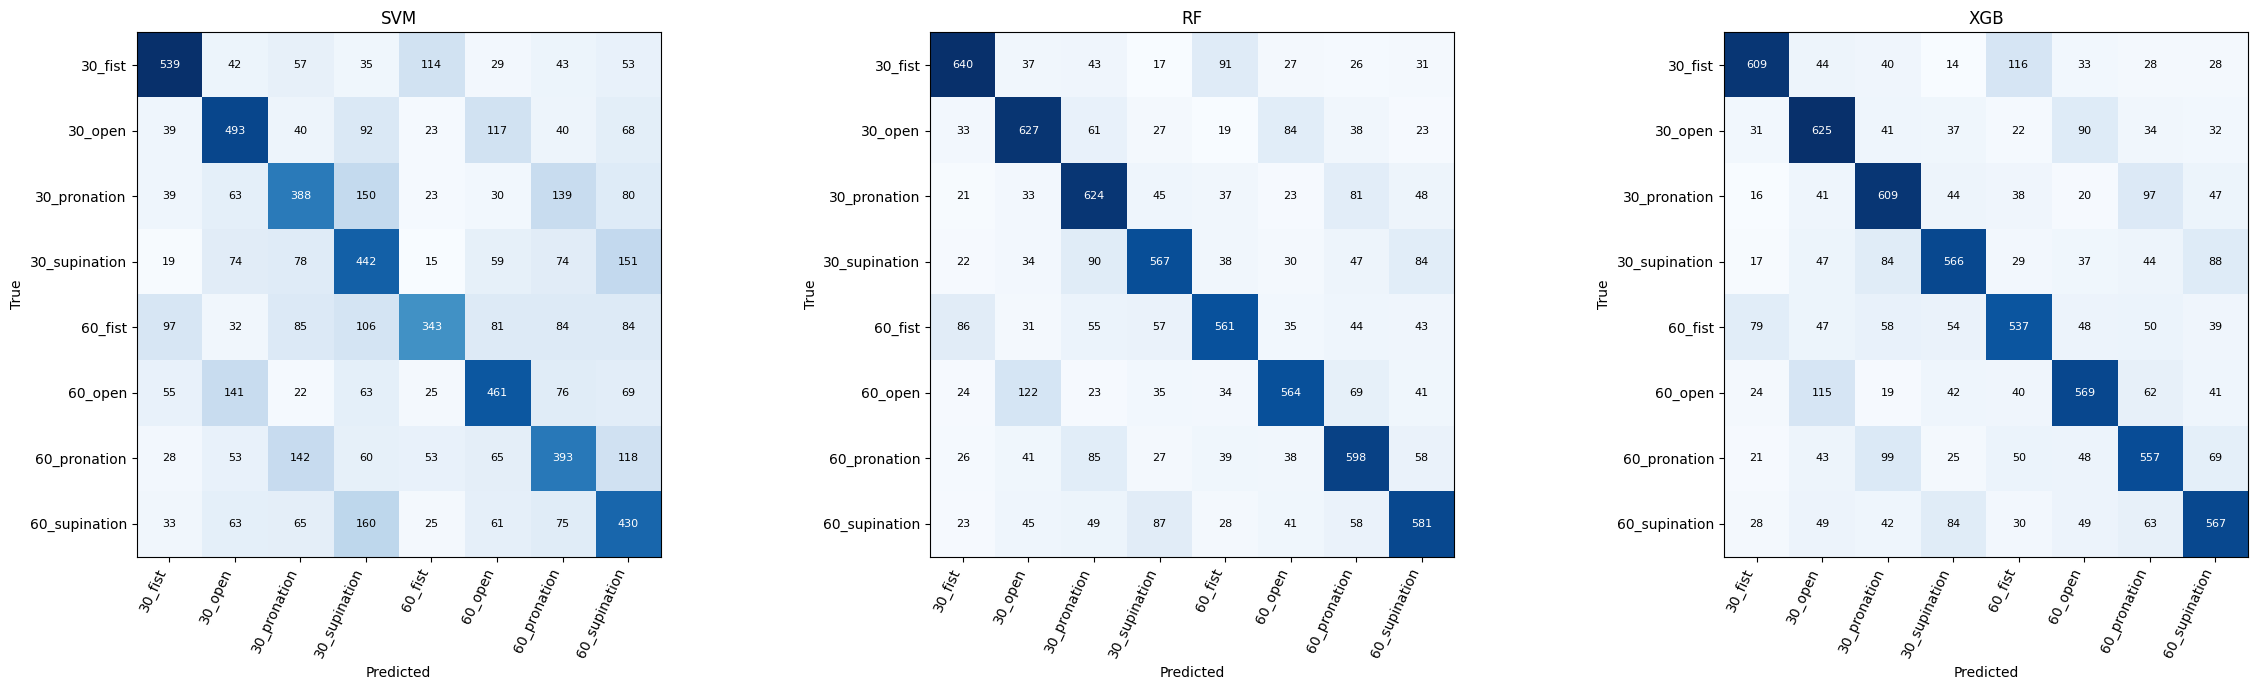


 SVM 클래스별 재현율


,Model,class,support,correct,recall
0,SVM,30_fist,912,539,0.591009
1,SVM,30_open,912,493,0.540570
2,SVM,30_pronation,912,388,0.425439
3,SVM,30_supination,912,442,0.484649
4,SVM,60_fist,912,343,0.376096
5,SVM,60_open,912,461,0.505482
6,SVM,60_pronation,912,393,0.430921
7,SVM,60_supination,912,430,0.471491


오류가 많은 방향별 클래스 쌍


,Model,true,predicted,count,type
52,SVM,60_supination,30_supination,160,angle_only
27,SVM,30_supination,60_supination,151,angle_only
16,SVM,30_pronation,30_supination,150,gesture_only
44,SVM,60_pronation,30_pronation,142,angle_only
36,SVM,60_open,30_open,141,angle_only



 RF 클래스별 재현율


...


 XGB 클래스별 재현율


,Model,class,support,correct,recall
16,XGB,30_fist,912,609,0.667763
17,XGB,30_open,912,625,0.685307
18,XGB,30_pronation,912,609,0.667763
19,XGB,30_supination,912,566,0.620614
20,XGB,60_fist,912,537,0.588816
21,XGB,60_open,912,569,0.623904
22,XGB,60_pronation,912,557,0.610746
23,XGB,60_supination,912,567,0.621711


오류가 많은 방향별 클래스 쌍


,Model,true,predicted,count,type
115,XGB,30_fist,60_fist,116,angle_only
148,XGB,60_open,30_open,115,angle_only
156,XGB,60_pronation,30_pronation,99,angle_only
131,XGB,30_pronation,60_pronation,97,angle_only
123,XGB,30_open,60_open,90,angle_only


type,angle_only,gesture_only,both
Model,,,
SVM,1061,1544,1202
RF,720,991,823
XGB,768,1045,844


In [ ]:
error_rows, class_rows = [], []
fig, axes = plt.subplots(1,3,figsize=(24,7))
cms = {}
for ax,(name,pred) in zip(axes,predictions.items()):
    cm = confusion_matrix(yte,pred,labels=class_ids); cms[name]=cm
    np.savetxt(RESULTS/f'confusion_{name}.csv',cm,fmt='%d',delimiter=',')
    ax.imshow(cm,cmap='Blues'); ax.set_title(name)
    ax.set_xticks(class_ids,classes,rotation=65,ha='right'); ax.set_yticks(class_ids,classes)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in class_ids:
        for j in class_ids:
            if cm[i,j]: ax.text(j,i,str(cm[i,j]),ha='center',va='center',
                fontsize=8,color='white' if cm[i,j]>cm.max()/2 else 'black')
        class_rows.append({'Model':name,'class':classes[i],
            'support':int(cm[i].sum()),'correct':int(cm[i,i]),
            'recall':float(cm[i,i]/cm[i].sum())})
        for j in class_ids:
            if i==j or cm[i,j]==0:continue
            ai,gi=classes[i].split('_',1); aj,gj=classes[j].split('_',1)
            kind=('angle_only' if gi==gj else 'gesture_only' if ai==aj else 'both')
            error_rows.append({'Model':name,'true':classes[i],'predicted':classes[j],
                               'count':int(cm[i,j]),'type':kind})
fig.tight_layout(); fig.savefig(FIGURES/'confusion8.png',dpi=180); plt.show()
for name,cm in cms.items():
    fig,ax=plt.subplots(figsize=(9,8)); ax.imshow(cm,cmap='Blues')
    ax.set_xticks(class_ids,classes,rotation=60,ha='right'); ax.set_yticks(class_ids,classes)
    ax.set(xlabel='Predicted',ylabel='True',title=name)
    for i in class_ids:
        for j in class_ids:
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=8,
                color='white' if cm[i,j]>cm.max()/2 else 'black')
    fig.tight_layout();fig.savefig(FIGURES/f'confusion_{name}.png',dpi=180);plt.close(fig)
errors=pd.DataFrame(error_rows,columns=['Model','true','predicted','count','type'])
per_class=pd.DataFrame(class_rows)
errors.to_csv(RESULTS/'error_pairs.csv',index=False)
per_class.to_csv(RESULTS/'class_recall.csv',index=False)
for name in models:
    print('\n',name,'클래스별 재현율');display(per_class[per_class.Model==name])
    print('오류가 많은 방향별 클래스 쌍')
    display(errors[errors.Model==name].sort_values('count',ascending=False).head(5))
error_types=(errors.groupby(['Model','type'])['count'].sum().unstack(fill_value=0)
             .reindex(index=list(models),columns=['angle_only','gesture_only','both'],fill_value=0))
display(error_types);error_types.to_csv(RESULTS/'error_types.csv')

## 9. 동일 시행 폴드 5-fold 교차검증
전체 시행 후보를 동일한 5개 폴드로 나눠 세 모델을 평가합니다.
매 폴드마다 모델을 새로 만들고, 그 폴드의 학습셋에서만 scaler를 fit합니다.
전체 윈도우를 무작위로 나누지 않습니다. 평균과 표준편차는 강의와 같이 ddof=0입니다.
이 CV는 전체 데이터의 내부 검증이며, hold-out에서 완전히 독립적인 검증은 아닙니다.

In [ ]:
skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
folds=list(skf.split(np.zeros(len(meta)),labels))
fold_rows=[]; fold_acc={name:[] for name in models}
oof={name:np.full((len(meta),19),-1,dtype=int) for name in models}
fold_id=np.zeros(len(meta),dtype=int)
for fold,(a,b) in enumerate(folds,1):
    assert set(a).isdisjoint(b)
    assert set(meta.iloc[a].trial_id).isdisjoint(meta.iloc[b].trial_id)
    Xa,ya=flatten(a); Xb,yb=flatten(b); fold_id[b]=fold
    for name,prototype in models.items():
        m=clone(prototype);m.fit(Xa,ya);pred=m.predict(Xb)
        scores=metrics(yb,pred)
        fold_rows.append({'fold':fold,'Model':name,**scores})
        fold_acc[name].append(scores['Accuracy'])
        oof[name][b]=pred.reshape(-1,19)
        print(f'fold {fold}/5 {name}: acc={scores["Accuracy"]*100:.2f}%')
    pd.DataFrame(fold_rows).to_csv(RESULTS/'cv_folds.csv',index=False)
cv=pd.DataFrame(fold_rows)
cv_summary=cv.groupby('Model')[list(holdout.columns)].agg(['mean',lambda s:s.std(ddof=0)])
cv_summary.columns=['_'.join([a,'mean' if b=='mean' else 'std']) for a,b in cv_summary.columns]
cv_summary=cv_summary.reindex(list(models));cv_summary.to_csv(RESULTS/'cv_summary.csv')
for name in models:
    assert (oof[name]>=0).all()
    print(f'{name}: {np.mean(fold_acc[name])*100:.2f} ± {np.std(fold_acc[name])*100:.2f}%')
display(cv.pivot(index='fold',columns='Model',values='Accuracy')*100)
manifest=meta.copy();manifest['validation_fold']=fold_id
manifest.to_csv(RESULTS/'cv_manifest.csv',index=False)
np.savez_compressed(RESULTS/'cv_oof_predictions.npz',y=labels,**oof)

fold 1/5 SVM: acc=46.93%
fold 1/5 RF: acc=64.56%
fold 1/5 XGB: acc=62.32%
fold 2/5 SVM: acc=47.90%
fold 2/5 RF: acc=65.34%
fold 2/5 XGB: acc=63.84%
fold 3/5 SVM: acc=47.67%
fold 3/5 RF: acc=64.04%
fold 3/5 XGB: acc=62.23%
fold 4/5 SVM: acc=47.51%
fold 4/5 RF: acc=63.47%
fold 4/5 XGB: acc=62.02%
fold 5/5 SVM: acc=47.86%
fold 5/5 RF: acc=65.31%
fold 5/5 XGB: acc=63.90%
SVM: 47.57 ± 0.35%
RF: 64.54 ± 0.72%
XGB: 62.86 ± 0.83%


Model,RF,SVM,XGB
fold,,,
1,64.555921,46.929825,62.321820
2,65.337171,47.902961,63.843202
3,64.035088,47.669956,62.225877
4,63.473136,47.505482,62.020285
5,65.309759,47.861842,63.898026


## 10. 폴드별 정확도의 대응표본 t 검정
세 쌍을 모두 비교합니다. 강의 기준의 양측 p값과 추가 참고용 Holm 보정 p값을 저장합니다.
p≥0.05는 차이를 검출하지 못했다는 뜻이며, 모델이 동등하다는 증거가 아닙니다.
5개 폴드는 적고 학습 데이터도 겹치므로 검정을 강한 일반화 근거로 사용하지 않습니다.
차이의 분산이 0인 경우 p값을 억지로 만들지 않고 검정 한계를 보고합니다.

In [ ]:
test_rows=[]
for a,b in combinations(models,2):
    av,bv=np.array(fold_acc[a]),np.array(fold_acc[b]);diff=av-bv
    if not np.isfinite(diff).all() or np.isclose(diff.std(ddof=1),0,atol=1e-12):
        t,p=np.nan,np.nan
        interpretation='차이의 분산이 0이거나 값이 유한하지 않아 t 검정 해석이 어렵습니다.'
    else:
        t,p=ttest_rel(av,bv)
        interpretation=('이번 5개 폴드의 정확도 차이가 유의수준 0.05에서 유의합니다.'
                        if p<0.05 else '이번 5개 폴드에서 유의한 차이를 검출하지 못했습니다. 동등함을 뜻하지 않습니다.')
    test_rows.append({'A':a,'B':b,'mean_diff_percentage_points':diff.mean()*100,
                      't':t,'p_raw':p,'interpretation':interpretation})
tests=pd.DataFrame(test_rows);tests['p_holm']=np.nan
valid=tests.index[np.isfinite(tests.p_raw)]
if len(valid)==3:
    ordered=tests.loc[valid].sort_values('p_raw').index
    adjusted=np.maximum.accumulate([min(1,tests.loc[i,'p_raw']*(3-j))
                                    for j,i in enumerate(ordered)])
    tests.loc[ordered,'p_holm']=adjusted
tests.to_csv(RESULTS/'paired_ttests.csv',index=False)
display(tests)

,A,B,mean_diff_percentage_points,t,p_raw,interpretation,p_holm
0,SVM,RF,-16.968202,-50.646763,9.095291e-07,이번 5개 폴드의 정확도 차이가 유의수준 0.05에서 유의합니다.,0.000003
1,SVM,XGB,-15.287829,-46.848181,1.241830e-06,이번 5개 폴드의 정확도 차이가 유의수준 0.05에서 유의합니다.,0.000003
2,RF,XGB,1.680373,10.825422,4.131056e-04,이번 5개 폴드의 정확도 차이가 유의수준 0.05에서 유의합니다.,0.000413


## 11. 추가 분석 — 시행 단위 다수결과 참가자별 결과
Step 1 예시의 수치나 모델은 사용하지 않습니다.
이번 프로젝트에서는 **윈도우 정확도와 시행 다수결 정확도**, **각도/동작 오류 구조**를 근거로 분석을 확장합니다.
동률이면 라벨 인코딩 순서가 앞선 클래스를 선택하고 동률 시행 수도 보고합니다.
다수결은 19개 윈도우를 모두 본 뒤의 결과이므로 실시간 단일 윈도우 성능과 구분합니다.
참가자별 결과는 같은 참가자의 다른 시행을 학습했을 수 있는 내부 평가입니다.

In [ ]:
trial_rows=[]; subject_rows=[]
for name,pred in predictions.items():
    trial_predictions=[]; ties=0
    for window_pred in pred.reshape(-1,19):
        counts=np.bincount(window_pred,minlength=8)
        ties+=int((counts==counts.max()).sum()>1)
        trial_predictions.append(int(np.argmax(counts)))
    trial_rows.append({'Model':name,'window_accuracy':accuracy_score(yte,pred),
        'trial_vote_accuracy':accuracy_score(labels[te_i],trial_predictions),'tie_trials':ties})
    subjects=np.repeat(te_meta.subject.to_numpy(),19)
    for subject in sorted(set(subjects)):
        mask=subjects==subject
        subject_rows.append({'Model':name,'subject':subject,'windows':int(mask.sum()),
                             **metrics(yte[mask],pred[mask])})
trial_comparison=pd.DataFrame(trial_rows);subject_comparison=pd.DataFrame(subject_rows)
display(trial_comparison);display(subject_comparison)
trial_comparison.to_csv(RESULTS/'trial_vote_comparison.csv',index=False)
subject_comparison.to_csv(RESULTS/'subject_metrics.csv',index=False)
environment={'python':sys.version,'platform':platform.platform(),
 'cpu':platform.processor(),'logical_cpu_count':os.cpu_count(),
 'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,
 'scikit-learn':sklearn.__version__,'xgboost':xgboost.__version__,
 'data_revision':DATA_REVISION,'seed':SEED,'threads_RF':-1,'threads_XGB':2}
(RESULTS/'environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')
(RESULTS/'model_parameters.json').write_text(json.dumps(
 {n:m.named_steps['model'].get_params() for n,m in models.items()},indent=2,default=str),encoding='utf-8')

,Model,window_accuracy,trial_vote_accuracy,tie_trials
0,SVM,0.478207,0.744792,25
1,RF,0.652686,0.971354,3
2,XGB,0.635828,0.953125,5


,Model,subject,windows,Accuracy,Precision,Recall,F1-score
0,SVM,a,1083,0.392428,0.408418,0.401159,0.394243
1,SVM,b,798,0.350877,0.355200,0.356798,0.340118
2,SVM,c,760,0.438158,0.490451,0.504396,0.431703
3,SVM,d,931,0.501611,0.499397,0.499110,0.492874
4,SVM,e,1045,0.422967,0.464550,0.438283,0.424287
5,SVM,f,1121,0.696699,0.694825,0.695998,0.688149
6,SVM,g,703,0.540541,0.541417,0.542434,0.507866
7,SVM,h,855,0.445614,0.454763,0.446436,0.428656
8,RF,a,1083,0.636196,0.629202,0.640690,0.630294
9,RF,b,798,0.571429,0.570317,0.578462,0.564535


1950